# Lottery Ticket Hypothesis on the employee churn data

**The hypothesis** (Frankle & Carbin, 2019): a large, randomly initialised neural network contains a small sub-network (a *winning ticket*) that, trained on its own **from its original starting weights**, can match the full network's accuracy.

**Procedure used here (iterative magnitude pruning with rewinding)**
1. Create a small network with random starting weights, `theta_0`.
2. Train it, then prune the smallest-magnitude weights.
3. **Rewind** the surviving weights to their original values from `theta_0` and train again.
4. Repeat. Each round the network is sparser.
5. **Control:** the same sparse structure with *fresh* random weights ("random re-init"). If the hypothesis holds strongly, the rewound ticket should beat this control.

> This is separate from the "lottery" in the main churn model, which is random *undersampling* of stayers to balance the data. Here the training data is balanced once with that undersampling, and the network experiment runs on top of it.

Pure NumPy - no deep-learning library needed.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SkPipe
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from imblearn.under_sampling import RandomUnderSampler

# ---- settings ----
N_SEEDS    = 10            # repeat the whole experiment with 10 different random starting weights
HIDDEN     = (64, 32)      # network: inputs -> 64 -> 32 -> 1
PRUNE_RATE = 0.20          # prune 20% of the remaining weights per layer each round (output layer: half that)
ROUNDS     = 15            # 15 rounds -> about 3.7% of weights left
# Training settings were chosen on a validation split carved out of the TRAINING data (test set never used for tuning)
EPOCHS, LR, BATCH, WD = 25, 0.003, 128, 0.1

## 1. Load and prepare the data
Same preparation as the main model: blank-filling, scaling, one-hot encoding, 80/20 split, then the undersampling lottery on the training set only. `employee_id` is not used.

In [2]:
NAME = "employee_churn_ecommerce_retail_5000_10cols.csv"
candidates = [Path(NAME), Path("data") / NAME, Path("..") / "data" / NAME, Path("..") / NAME]
DATA_PATH = next((p for p in candidates if p.exists()), None)
assert DATA_PATH is not None, f"Could not find {NAME}. Put it next to this notebook or in a data/ folder."

df = pd.read_csv(DATA_PATH)
y = df["termination_date"].notna().astype(int).values        # blank termination date = still employed
X = df.drop(columns=["termination_date", "employee_id"])
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

num = Xtr.select_dtypes(include="number").columns.tolist()
cat = Xtr.select_dtypes(exclude="number").columns.tolist()
pre = ColumnTransformer([
    ("n", SkPipe([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), num),
    ("c", SkPipe([("i", SimpleImputer(strategy="most_frequent")),
                  ("o", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat)])
Ztr = pre.fit_transform(Xtr).astype(float)
Zte = pre.transform(Xte).astype(float)
Ztr, ytr_b = RandomUnderSampler(sampling_strategy=0.45, random_state=42).fit_resample(Ztr, ytr)   # data lottery (balancing)
D = Ztr.shape[1]
print(f"File: {DATA_PATH}")
print(f"Churn rate: {y.mean():.1%} | training rows after undersampling: {len(ytr_b)} ({ytr_b.sum()} leavers) | network inputs: {D} | test employees: {len(yte)}")

File: employee_churn_ecommerce_retail_5000_10cols.csv
Churn rate: 12.3% | training rows after undersampling: 1578 (490 leavers) | network inputs: 20 | test employees: 1000


## 2. The neural network, training and pruning
A small fully-connected network (ReLU) trained with Adam. A **mask** of 1s and 0s marks which weights are alive; pruned weights stay at zero.

In [3]:
sizes = (D,) + HIDDEN + (1,)

def init_weights(rng):
    W = [rng.normal(0, np.sqrt(2.0 / sizes[i]), (sizes[i], sizes[i + 1])) for i in range(len(sizes) - 1)]
    b = [np.zeros(sizes[i + 1]) for i in range(len(sizes) - 1)]
    return W, b

def forward(W, b, Xb):
    acts = [Xb]
    for i in range(len(W)):
        z = acts[-1] @ W[i] + b[i]
        acts.append(z if i == len(W) - 1 else np.maximum(z, 0))
    return acts

def predict(W, b, Xb):
    return 1 / (1 + np.exp(-forward(W, b, Xb)[-1][:, 0]))

def train(W, b, masks, rng):
    """Train with Adam; masked (pruned) weights are forced to stay zero."""
    W = [w * m for w, m in zip(W, masks)]; b = [x.copy() for x in b]
    mW = [np.zeros_like(w) for w in W]; vW = [np.zeros_like(w) for w in W]
    mb = [np.zeros_like(x) for x in b]; vb = [np.zeros_like(x) for x in b]; t = 0
    n = len(ytr_b)
    for _ in range(EPOCHS):
        idx = rng.permutation(n)
        for s in range(0, n, BATCH):
            ib = idx[s:s + BATCH]; acts = forward(W, b, Ztr[ib])
            p = 1 / (1 + np.exp(-acts[-1][:, 0])); delta = ((p - ytr_b[ib]) / len(ib))[:, None]
            t += 1
            for i in range(len(W) - 1, -1, -1):
                gW = acts[i].T @ delta + WD * W[i]; gb = delta.sum(0)
                if i > 0: delta = (delta @ W[i].T) * (acts[i] > 0)
                gW = gW * masks[i]
                for (m_, v_, g_, par) in ((mW, vW, gW, W), (mb, vb, gb, b)):
                    m_[i] = 0.9 * m_[i] + 0.1 * g_; v_[i] = 0.999 * v_[i] + 0.001 * g_ ** 2
                    par[i] = par[i] - LR * (m_[i] / (1 - 0.9 ** t)) / (np.sqrt(v_[i] / (1 - 0.999 ** t)) + 1e-8)
                W[i] = W[i] * masks[i]
    return W, b

def prune(W, masks):
    """Remove the smallest-magnitude surviving weights in each layer."""
    new = []
    for i, (w, m) in enumerate(zip(W, masks)):
        rate = PRUNE_RATE if i < len(W) - 1 else PRUNE_RATE / 2
        alive = np.abs(w[m == 1]); k = int(round(rate * alive.size))
        if k > 0 and alive.size > 1:
            cut = np.partition(alive, k - 1)[k - 1]; m = m * (np.abs(w) > cut)
        new.append(m)
    return new

def fa_at_recall(p, r=0.60):
    f, t, _ = roc_curve(yte, p)
    return 1000 * f[np.searchsorted(t, r)]          # false alarms per 1,000 stayers at the given recall

def score(W, b):
    p = predict(W, b, Zte)
    return roc_auc_score(yte, p), average_precision_score(yte, p), fa_at_recall(p)

total = sum(w.size for w in init_weights(np.random.default_rng(0))[0])
print(f"Network {' -> '.join(map(str, sizes))} with {total} weights")

Network 20 -> 64 -> 32 -> 1 with 3360 weights


## 3. Run the experiment
For each seed and each pruning round: train the **winning ticket** (survivors rewound to the original starting weights) and the **random re-init** control (same mask, new random weights), then score both on the untouched test set. Takes about 30 seconds.

In [4]:
records = []
for seed in range(N_SEEDS):
    W0, b0 = init_weights(np.random.default_rng(100 + seed))            # theta_0 (the original starting weights)
    masks = [np.ones_like(w) for w in W0]
    for rnd in range(ROUNDS + 1):
        remaining = 100 * sum(m.sum() for m in masks) / total
        rng_t = np.random.default_rng(1000 + seed * 100 + rnd)
        Wt, bt = train(W0, b0, masks, rng_t)                            # ticket: rewound to ORIGINAL init
        Wr0, br0 = init_weights(np.random.default_rng(5000 + seed * 100 + rnd))
        Wr, br = train(Wr0, br0, masks, rng_t)                          # control: same mask, FRESH init
        for kind, (W_, b_) in (("winning ticket", (Wt, bt)), ("random re-init", (Wr, br))):
            auc, ap, fa = score(W_, b_)
            records.append(dict(seed=seed, round=rnd, remaining=remaining, kind=kind, auc=auc, pr_auc=ap, fa60=fa))
        masks = prune(Wt, masks)                                        # prune using the trained ticket weights
    print(f"seed {seed + 1}/{N_SEEDS} done")

res = pd.DataFrame(records)

seed 1/10 done


seed 2/10 done


seed 3/10 done


seed 4/10 done


seed 5/10 done


seed 6/10 done


seed 7/10 done


seed 8/10 done


seed 9/10 done


seed 10/10 done


## 4. Results table
Test ROC AUC (mean and spread over seeds) at each sparsity level, plus false alarms per 1,000 stayers when catching 60% of leavers. Logistic regression on the same balanced data is the reference.

In [5]:
agg = res.groupby(["kind", "round"]).agg(remaining=("remaining", "mean"), auc=("auc", "mean"), auc_sd=("auc", "std"),
                                         pr=("pr_auc", "mean"), fa60=("fa60", "mean")).reset_index()
wt = agg[agg.kind == "winning ticket"].set_index("round")
rr = agg[agg.kind == "random re-init"].set_index("round")

lr = LogisticRegression(max_iter=1000).fit(Ztr, ytr_b)
p_lr = lr.predict_proba(Zte)[:, 1]
lr_auc, lr_fa = roc_auc_score(yte, p_lr), fa_at_recall(p_lr)

table = pd.DataFrame({
    "weights left (%)": wt.remaining.round(1),
    "ticket AUC": wt.auc.round(3), "ticket sd": wt.auc_sd.round(3),
    "re-init AUC": rr.auc.round(3), "re-init sd": rr.auc_sd.round(3),
    "ticket - re-init": (wt.auc - rr.auc).round(3),
    "false alarms/1000 (ticket)": wt.fa60.round(0), "false alarms/1000 (re-init)": rr.fa60.round(0)})
print(f"Reference - logistic regression: AUC {lr_auc:.3f} | false alarms per 1,000 stayers at 60% recall: {lr_fa:.0f}")
table.reset_index(drop=True)

Reference - logistic regression: AUC 0.738 | false alarms per 1,000 stayers at 60% recall: 238


,weights left (%),ticket AUC,ticket sd,re-init AUC,re-init sd,ticket - re-init,false alarms/1000 (ticket),false alarms/1000 (re-init)
0,100.0,0.744,0.002,0.742,0.002,0.002,235.0,241.0
1,80.1,0.744,0.001,0.743,0.002,0.001,237.0,242.0
2,64.1,0.744,0.001,0.743,0.002,0.001,236.0,238.0
3,51.4,0.744,0.001,0.742,0.002,0.001,235.0,239.0
4,41.2,0.744,0.001,0.742,0.002,0.001,238.0,237.0
5,33.0,0.743,0.001,0.744,0.002,-0.000,238.0,237.0
6,26.4,0.744,0.001,0.743,0.001,0.001,237.0,237.0
7,21.2,0.744,0.002,0.743,0.002,0.001,237.0,235.0
8,17.0,0.744,0.001,0.743,0.001,0.001,237.0,233.0
9,13.6,0.744,0.002,0.744,0.001,0.000,236.0,226.0


## 5. Plot: ranking quality and false alarms as the network gets sparser
The x-axis runs from dense (left) to very sparse (right). The shaded band is one standard deviation across seeds.

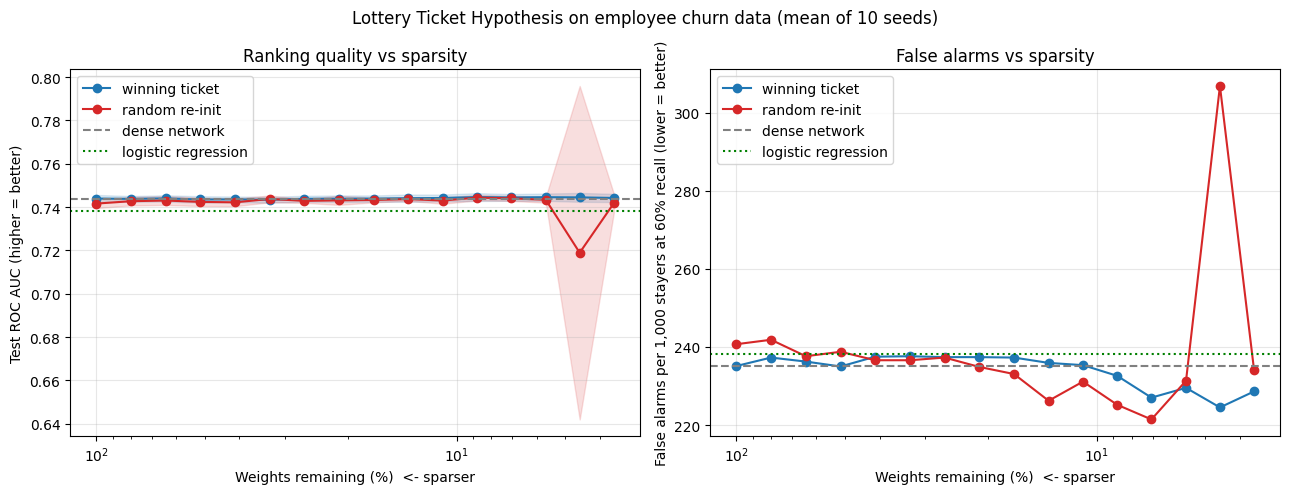

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for kind, col in (("winning ticket", "#1f77b4"), ("random re-init", "#d62728")):
    a = agg[agg.kind == kind]
    ax[0].plot(a.remaining, a.auc, "o-", color=col, label=kind)
    ax[0].fill_between(a.remaining, a.auc - a.auc_sd, a.auc + a.auc_sd, color=col, alpha=0.15)
    ax[1].plot(a.remaining, a.fa60, "o-", color=col, label=kind)
ax[0].axhline(wt.auc[0], ls="--", color="gray", label="dense network")
ax[0].axhline(lr_auc, ls=":", color="green", label="logistic regression")
ax[1].axhline(wt.fa60[0], ls="--", color="gray", label="dense network")
ax[1].axhline(lr_fa, ls=":", color="green", label="logistic regression")
for a_, yl, tt in ((ax[0], "Test ROC AUC (higher = better)", "Ranking quality vs sparsity"),
                   (ax[1], "False alarms per 1,000 stayers at 60% recall (lower = better)", "False alarms vs sparsity")):
    a_.set_xscale("log"); a_.invert_xaxis()
    a_.set_xlabel("Weights remaining (%)  <- sparser"); a_.set_ylabel(yl); a_.set_title(tt)
    a_.grid(alpha=0.3); a_.legend()
fig.suptitle(f"Lottery Ticket Hypothesis on employee churn data (mean of {N_SEEDS} seeds)")
fig.tight_layout()
# fig.savefig("lottery_ticket_results.png", dpi=150)   # uncomment to save the picture
plt.show()

## 6. Does rewinding actually help? Paired comparison
For every seed and sparsity level, subtract the control's AUC from the ticket's AUC. A real lottery-ticket effect would show a clearly positive difference, especially at high sparsity.

In [7]:
p = res.pivot_table(index=["seed", "round"], columns="kind", values="auc")
d = p["winning ticket"] - p["random re-init"]
collapsed = p["random re-init"] < 0.6
print(f"Runs compared: {len(d)}")
print(f"Mean AUC difference (ticket - re-init): {d.mean():+.4f}   median: {d.median():+.4f}")
print(f"Ticket better in {(d > 0).mean():.0%} of runs")
print(f"Mean difference excluding collapsed runs: {d[~collapsed].mean():+.4f}")
print(f"Typical seed-to-seed noise (sd of ticket AUC): {wt.auc_sd.mean():.4f}")
print(f"\nRe-init runs that failed to train (AUC < 0.6): {int(collapsed.sum())}  |  winning-ticket runs that failed: {int((p['winning ticket'] < 0.6).sum())}")
res[(res.kind == "random re-init") & (res.auc < 0.6)][["seed", "round", "remaining", "auc"]].round(3)

Runs compared: 160
Mean AUC difference (ticket - re-init): +0.0025   median: +0.0012
Ticket better in 70% of runs
Mean difference excluding collapsed runs: +0.0010
Typical seed-to-seed noise (sd of ticket AUC): 0.0016

Re-init runs that failed to train (AUC < 0.6): 1  |  winning-ticket runs that failed: 0


,seed,round,remaining,auc
157,4,14,4.554,0.5


## 7. Conclusions (original data, 12.3% churn)

- **Sparse networks work.** The network keeps its test AUC (about 0.744) with about 96% of its weights removed, so the weak form of the hypothesis holds.
- **The rewind adds almost nothing.** The winning ticket beats the random re-init by only about 0.001-0.003 AUC on average, less than the seed-to-seed noise (about 0.002). The key claim of the hypothesis - a clear gap between ticket and re-init - is not visible here.
- **One mildly supportive result:** at about 4.6% of weights, one random re-init run failed to train (AUC 0.500) while every winning ticket trained. That is the pattern the hypothesis predicts, but it is a single run - do not oversell it.
- **Why the effect is small:** the churn data is close to a straight-line problem and the network has far more weights than it needs, so it can be shrunk a lot from almost any starting point.
- **No gain over the simple model:** the network's AUC (about 0.744) is within noise of logistic regression (about 0.738), consistent with about 0.75 being the ceiling of the information in these columns. The final model stays logistic regression.

**Caveats:** small network, small dataset, NumPy implementation, layer-wise magnitude pruning, a single train/test split. Treat this as a demonstration, not a definitive test of the hypothesis.